In [1]:
import matplotlib.pyplot as plt                          
import seaborn as sns
import os
import pickle
import numpy as np
import pandas as pd
from itertools import combinations

In [2]:
human_attr_list = ['male', 'heavy makeup', 'wearing earrings', 'black hair', 'blond hair',
                   'wearing eyeglasses', 'wearing hat', 'young', 'with beard', 'smiling',
                   ]
animal_attr_list = ['dog', 'cat', 'tiger', 'lion', 'bear', 'elephant', 'giraffe', 'zebra',
                    'wolf', 'fox', 'rabbit', 'squirrel', 'eagle', 'penguin', 'dolphin',
                    'whale', 'snake', 'turtle', 'frog', 'butterfly']
furniture_attr_list = ['sofa', 'chair', 'bed', 'table', 'closet', 'bookshelf', 'mirror', 'nightstand',
                       'carpet', 'television', 'refrigerator', 'washing machine', 'microwave oven', 'bowl',
                       'plate', 'cup', 'curtain', 'pillow', 'clock', 'computer']

# Single Attribute Divergence (SaD) & Paired Attribute Divergence (PaD)
------
- ### SaD
#### Plotting both line and bar charts:
#### 1) Using mean values of all attributes
#### 2) Only considering ' wearing eyeglasses' instead of using mean values of all attributes

- ### PaD
#### Plotting both line and bar charts:
#### 1) Using mean values of all attributes
#### 2) Only consider attribute combinations in same category, i.e. human-related attributes

In [3]:
def my_key(dir_name):
    return int(dir_name.split('_')[-1])

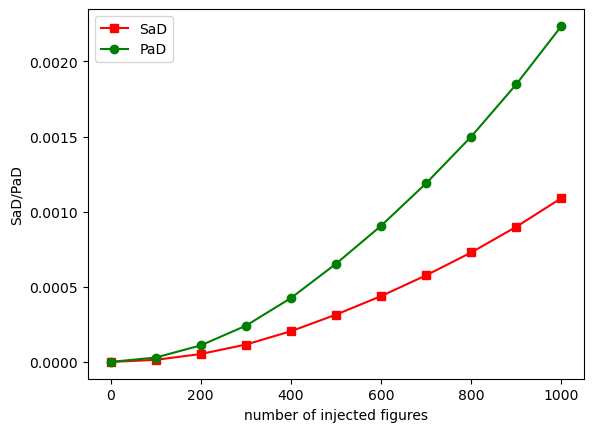

In [4]:
x = list(range(0,1100,100))#点的横坐标
# read experiment results from the path
base_path = '/Users/yifanlu/PycharmProjects/interpretable_evaluation_metrics/results_dir/celebA_50_USER_HCS'
dirs = sorted((f for f in os.listdir(base_path) if f.startswith("CelebA5k")), key=my_key)
sad = [0]
pad = [0]
for dir in dirs:
    dir_path = os.path.join(base_path, dir)
    with open(f'{dir_path}/experiment_results_dict.pkl', 'rb') as f:
        results = pickle.load(f)
        sad.append(results['forward_KL_single'].mean())
        pad.append(results['forward_KL_pair'].mean())       
plt.plot(x,sad,'s-',color = 'r',label="SaD")    #s-:方形        
plt.plot(x,pad,'o-',color = 'g',label="PaD")    #o-:圆形        
plt.xlabel("number of injected figures")    #横坐标名字           
plt.ylabel("SaD/PaD")    #纵坐标名字                              
plt.legend(loc = "best")    #图例                              
plt.savefig('hcs_GD_FKL.png', bbox_inches='tight')            
plt.show()

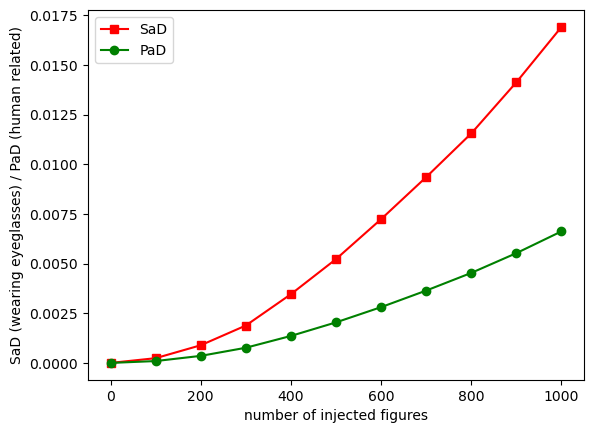

In [5]:
x = list(range(0,1100,100))
# read experiment results from the path
base_path = '/Users/yifanlu/PycharmProjects/interpretable_evaluation_metrics/results_dir/celebA_50_USER_HCS'
dirs = sorted((f for f in os.listdir(base_path) if f.startswith("CelebA5k")), key=my_key)
sad = [0]
pad = [0]
for dir in dirs:
    dir_path = os.path.join(base_path, dir)
    with open(f'{dir_path}/experiment_results_dict.pkl', 'rb') as f:
        results = pickle.load(f)
        attr_list = results['attr_list']
        # find index of the target attribute
        target_attr = 'wearing eyeglasses'
        assert target_attr in attr_list
        target_attr_index = attr_list.index(target_attr)
        sad.append(results['forward_KL_single'][target_attr_index])

        all_combinations = [pair for pair in combinations(attr_list, 2)]
        human_combinations = [pair for pair in combinations(human_attr_list, 2)]
        target_attr_indices = [i for i,a in enumerate(all_combinations) if a in human_combinations]
        pad.append(results['forward_KL_pair'][target_attr_indices].mean())
plt.plot(x,sad,'s-',color = 'r',label="SaD")    #s-:方形        
plt.plot(x,pad,'o-',color = 'g',label="PaD")    #o-:圆形        
plt.xlabel("number of injected figures")    #横坐标名字           
plt.ylabel("SaD (wearing eyeglasses) / PaD (human related)")    #纵坐标名字                              
plt.legend(loc = "best")    #图例                              
plt.savefig('hcs_wearing_eyeglasses_GD_FKL.png', bbox_inches='tight')              
plt.show()

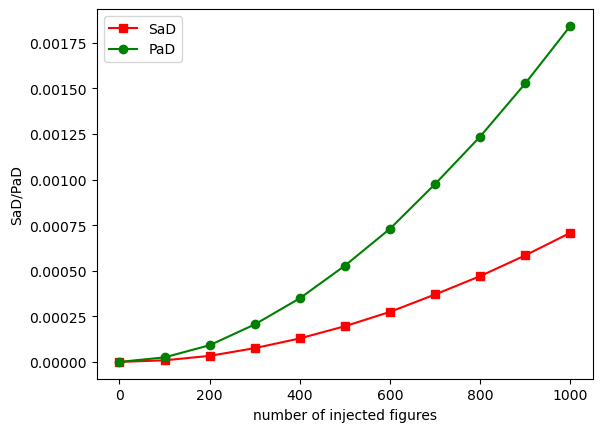

In [6]:
x = list(range(0,1100,100))#点的横坐标
# read experiment results from the path
base_path = '/Users/yifanlu/PycharmProjects/interpretable_evaluation_metrics/results_dir/celebA_50_USER_dualCS'
dirs = sorted((f for f in os.listdir(base_path) if f.startswith("CelebA5k")), key=my_key)
sad = [0]
pad = [0]
for dir in dirs:
    dir_path = os.path.join(base_path, dir)
    with open(f'{dir_path}/experiment_results_dict.pkl', 'rb') as f:
        results = pickle.load(f)
        sad.append(results['forward_KL_single'].mean())
        pad.append(results['forward_KL_pair'].mean())       
plt.plot(x,sad,'s-',color = 'r',label="SaD")    #s-:方形        
plt.plot(x,pad,'o-',color = 'g',label="PaD")    #o-:圆形        
plt.xlabel("number of injected figures")    #横坐标名字           
plt.ylabel("SaD/PaD")    #纵坐标名字                              
plt.legend(loc = "best")    #图例                              
plt.savefig('dualcs_GD_FKL.png', bbox_inches='tight')            
plt.show()

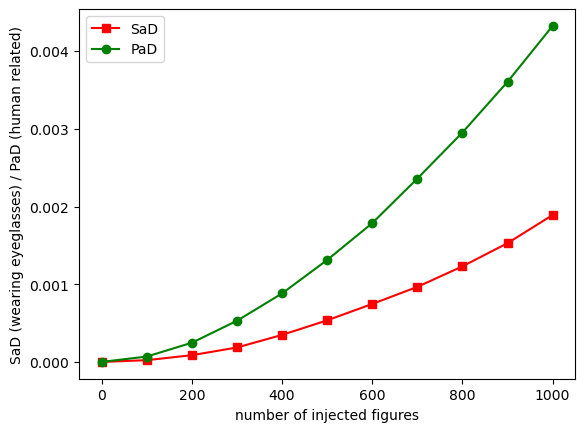

In [7]:
x = list(range(0,1100,100))
# read experiment results from the path
base_path = '/Users/yifanlu/PycharmProjects/interpretable_evaluation_metrics/results_dir/celebA_50_USER_dualCS'
dirs = sorted((f for f in os.listdir(base_path) if f.startswith("CelebA5k")), key=my_key)
sad = [0]
pad = [0]
for dir in dirs:
    dir_path = os.path.join(base_path, dir)
    with open(f'{dir_path}/experiment_results_dict.pkl', 'rb') as f:
        results = pickle.load(f)
        attr_list = results['attr_list']
        # find index of the target attribute
        target_attr = 'wearing eyeglasses'
        assert target_attr in attr_list
        target_attr_index = attr_list.index(target_attr)
        sad.append(results['forward_KL_single'][target_attr_index])

        all_combinations = [pair for pair in combinations(attr_list, 2)]
        human_combinations = [pair for pair in combinations(human_attr_list, 2)]
        target_attr_indices = [i for i,a in enumerate(all_combinations) if a in human_combinations]
        pad.append(results['forward_KL_pair'][target_attr_indices].mean())       
plt.plot(x,sad,'s-',color = 'r',label="SaD")    #s-:方形        
plt.plot(x,pad,'o-',color = 'g',label="PaD")    #o-:圆形        
plt.xlabel("number of injected figures")    #横坐标名字           
plt.ylabel("SaD (wearing eyeglasses) / PaD (human related)")    #纵坐标名字                              
plt.legend(loc = "best")    #图例                              
plt.savefig('dualcs_wearing_eyeglasses_GD_FKL.png', bbox_inches='tight')              
plt.show()

----

In [10]:
def plot_bar(result, labels, name, save_path=None):
    # check if results has the same length as labels
    assert len(result) == len(labels)

    fig = plt.figure()
    ax = fig.add_subplot(111)
    ax.set_xticks(np.arange(len(labels)))
    ax.set_xticklabels(labels, rotation=90)
    ax.bar(labels, result, width=0.8)

    plt.title(f"{name} \n mean={np.sum(result)/(result.shape[0])}, var={np.var(result, dtype=np.float32)}")
    plt.ylabel('each attribute difference between 2 datasets', fontsize=5)
    plt.tight_layout()
    plt.savefig(f"{save_path}.png", dpi=2000)
    plt.show()


def plot_single(result, attr_list, save_path):
    target_attr_indices = [i for i,a in enumerate(attr_list) if a in human_attr_list]
    result = result[target_attr_indices]
    attr_list_sort_by_result = [human_attr_list[j] for j in result.argsort()[::-1]]
    result[::-1].sort()
    plot_bar(result, attr_list_sort_by_result, 'forward_KL', save_path)
    return


def plot_pair(result, attr_list, save_path, max_bar=20):
    all_pair_attr_list = [pair for pair in combinations(attr_list, 2)]
    human_pair_attr_list = [pair for pair in combinations(human_attr_list, 2)]
    target_attr_indices = [i for i,a in enumerate(all_pair_attr_list) if a in human_pair_attr_list]
    result = result[target_attr_indices]
    max_bar = min(max_bar, len(human_pair_attr_list))

    pair_attr_list_sort_by_result = [str(human_pair_attr_list[j]) for j in result.argsort()[::-1]]
    result[::-1].sort()
    plot_bar(result[:max_bar], pair_attr_list_sort_by_result[:max_bar], 'forward_KL', save_path)
    return

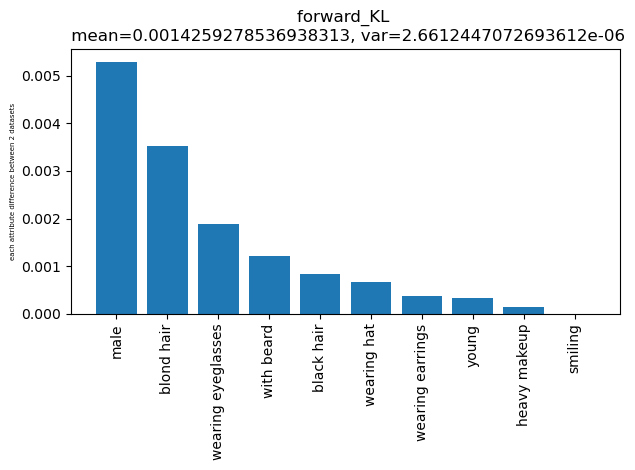

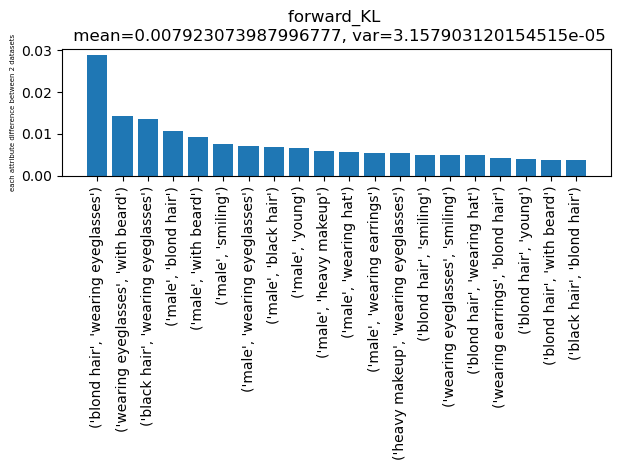

In [11]:
#柱状图                                                   
dir_path = '/Users/yifanlu/PycharmProjects/interpretable_evaluation_metrics/results_dir/celebA_50_USER_dualCS/CelebA5k_furniture15k_vs_CelebA5k_furniture15k_Eyeglasses_Injection_1000'
with open(f'{dir_path}/experiment_results_dict.pkl', 'rb') as f:
    results = pickle.load(f)
    attr_list = results['attr_list']
    sad_fkl = results['forward_KL_single']
    pad_fkl = results['forward_KL_pair']
plot_single(sad_fkl, attr_list, './dualcs_inj1000_sad_bar.png')
plot_pair(pad_fkl, attr_list, './dualcs_inj1000_pad_bar.png')

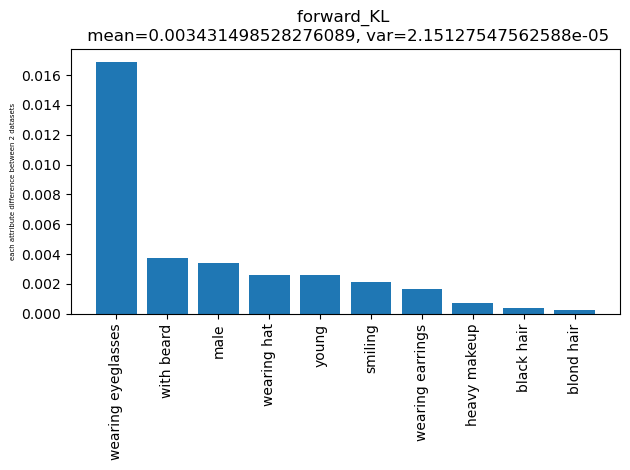

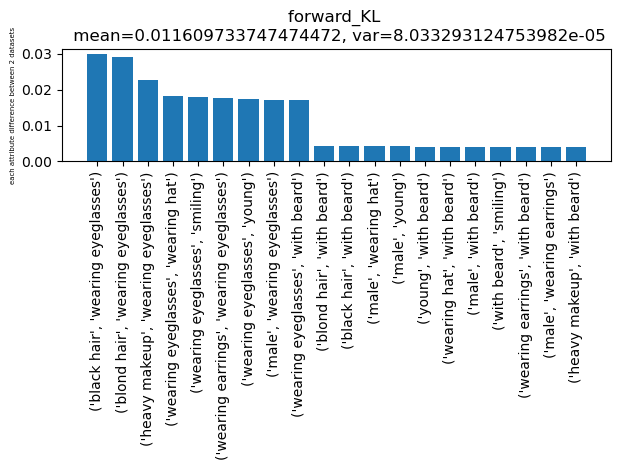

In [12]:
dir_path = '/Users/yifanlu/PycharmProjects/interpretable_evaluation_metrics/results_dir/celebA_50_USER_HCS/CelebA5k_furniture15k_vs_CelebA5k_furniture15k_Eyeglasses_Injection_1000'
with open(f'{dir_path}/experiment_results_dict.pkl', 'rb') as f:
    results = pickle.load(f)
    attr_list = results['attr_list']
    sad_fkl = results['forward_KL_single']
    pad_fkl = results['forward_KL_pair']
plot_single(sad_fkl, attr_list, './hcs_inj1000_sad_bar.png')
plot_pair(pad_fkl, attr_list, './hcs_inj1000_pad_bar.png')

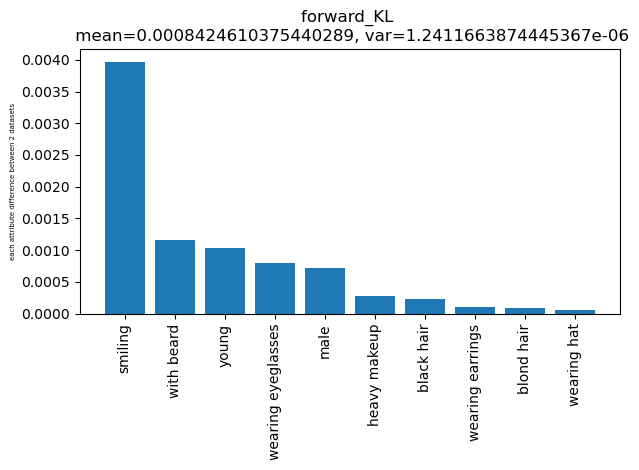

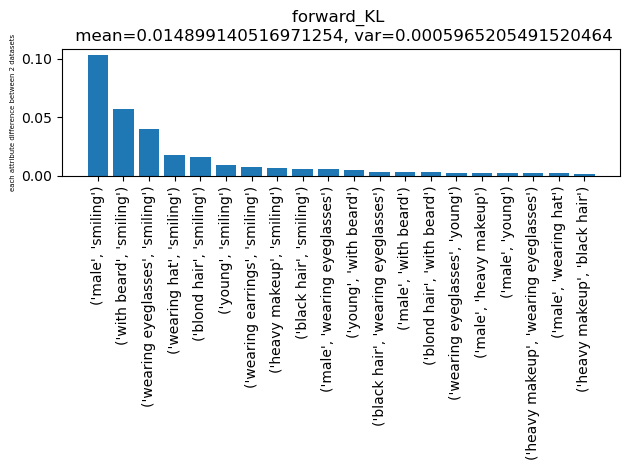

In [13]:
dir_path = '/Users/yifanlu/PycharmProjects/interpretable_evaluation_metrics/results_dir/celebA_50_USER_dualCS/furniture5k_nsmsw1_vs_furniture5k_smnsw1'
with open(f'{dir_path}/experiment_results_dict.pkl', 'rb') as f:
    results = pickle.load(f)
    attr_list = results['attr_list']
    sad_fkl = results['forward_KL_single']
    pad_fkl = results['forward_KL_pair']
plot_single(sad_fkl, attr_list, './dualcs_nsmsw1_vs_smnsw1_sad_bar.png')
plot_pair(pad_fkl, attr_list, './dualcs_nsmsw1_vs_smnsw1_pad_bar.png')

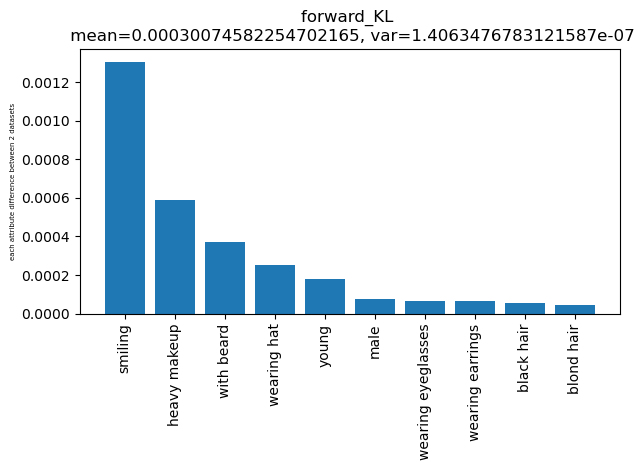

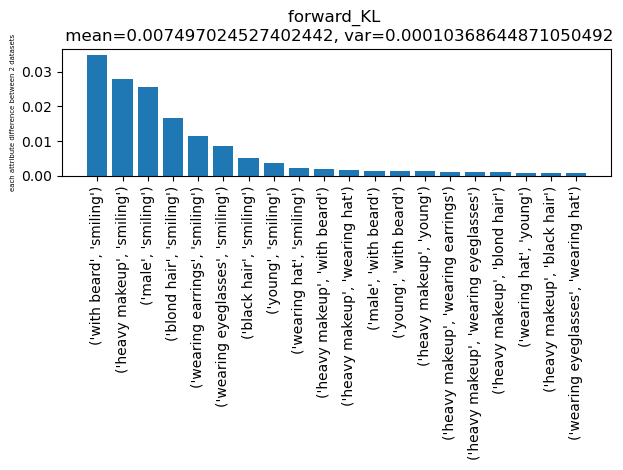

In [24]:
dir_path = '/Users/yifanlu/PycharmProjects/interpretable_evaluation_metrics/results_dir/celebA_50_USER_HCS/furniture5k_nsmsw1_vs_furniture5k_smnsw1'
with open(f'{dir_path}/experiment_results_dict.pkl', 'rb') as f:
    results = pickle.load(f)
    attr_list = results['attr_list']
    sad_fkl = results['forward_KL_single']
    pad_fkl = results['forward_KL_pair']
plot_single(sad_fkl, attr_list, './hcs_nsmsw1_vs_smnsw1_sad_bar.png')
plot_pair(pad_fkl, attr_list, './hcs_nsmsw1_vs_smnsw1_pad_bar.png')

# Heatmaps of Covariance Matrix
--------
#### Goal: to check if PaD can be replaced with identifying changes of covariance matrix

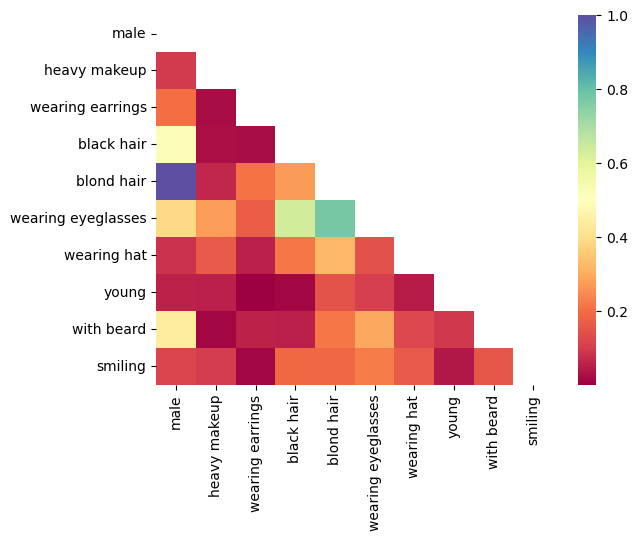

In [22]:
path = '/Users/yifanlu/PycharmProjects/interpretable_evaluation_metrics/results_dir/celebA_50_USER_dualCS/CelebA5k_furniture15k_vs_CelebA5k_furniture15k_Eyeglasses_Injection_1000/experiment_results_dict.pkl'
with open(path, 'rb') as f:
        results = pickle.load(f)
        scores_real = results['scores_real']
        scores_gen = results['scores_gen']
        scores_mean_real = scores_real.mean(axis=0)  # shape: n_attr
        scores_mean_gen = scores_gen.mean(axis=0)
        scores_cov_real = np.cov(scores_real.T)[:10,:10]  # phi^2 = EX² - x_mean², shape: n_attr*n_attr
        scores_cov_gen = np.cov(scores_gen.T)[:10,:10]
        scores_cov_real /= np.abs(scores_cov_real).max()
        scores_cov_gen /= np.abs(scores_cov_gen).max()
        scores_cov_diff = np.abs(scores_cov_real - scores_cov_gen)
        cov = pd.DataFrame(scores_cov_diff/scores_cov_diff.max(), index = human_attr_list,
                  columns = human_attr_list)
        mask = np.zeros_like(cov, dtype=bool)
        mask[np.triu_indices_from(mask)] = True
        sns.heatmap(cov, mask=mask, cmap="Spectral")

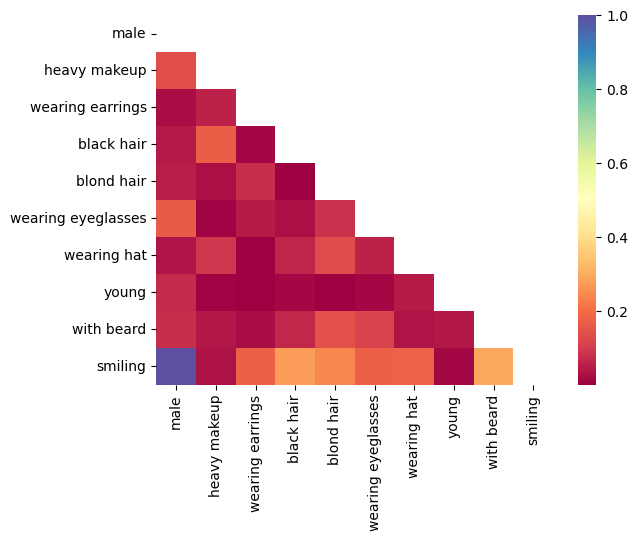

In [23]:
path = '/Users/yifanlu/PycharmProjects/interpretable_evaluation_metrics/results_dir/celebA_50_USER_dualCS/furniture5k_nsmsw1_vs_furniture5k_smnsw1/experiment_results_dict.pkl'
with open(path, 'rb') as f:
        results = pickle.load(f)
        scores_real = results['scores_real']
        scores_gen = results['scores_gen']
        scores_mean_real = scores_real.mean(axis=0)  # shape: n_attr
        scores_mean_gen = scores_gen.mean(axis=0)
        scores_cov_real = np.cov(scores_real.T)[:10,:10]  # phi^2 = EX² - x_mean², shape: n_attr*n_attr
        scores_cov_gen = np.cov(scores_gen.T)[:10,:10]
        scores_cov_real /= np.abs(scores_cov_real).max()
        scores_cov_gen /= np.abs(scores_cov_gen).max()
        scores_cov_diff = np.abs(scores_cov_real - scores_cov_gen)
        cov = pd.DataFrame(scores_cov_diff/scores_cov_diff.max(), index = human_attr_list,
                  columns = human_attr_list)
        mask = np.zeros_like(cov, dtype=bool)
        mask[np.triu_indices_from(mask)] = True
        sns.heatmap(cov, mask=mask, cmap="Spectral")

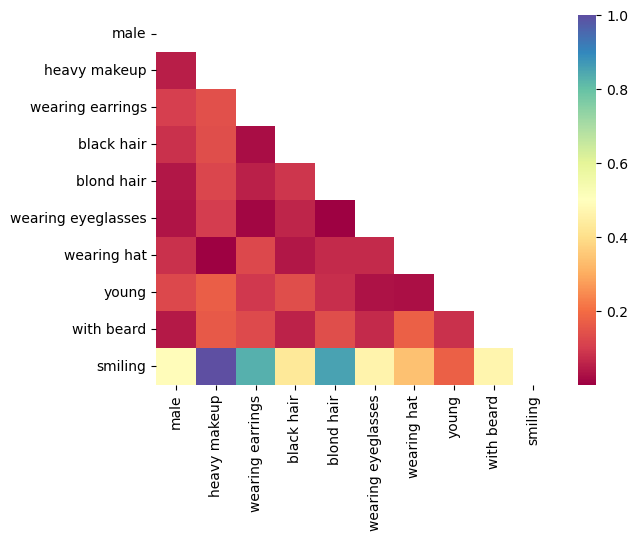

In [25]:
path = '/Users/yifanlu/PycharmProjects/interpretable_evaluation_metrics/results_dir/celebA_50_USER_HCS/furniture5k_nsmsw1_vs_furniture5k_smnsw1/experiment_results_dict.pkl'
with open(path, 'rb') as f:
        results = pickle.load(f)
        scores_real = results['scores_real']
        scores_gen = results['scores_gen']
        scores_mean_real = scores_real.mean(axis=0)  # shape: n_attr
        scores_mean_gen = scores_gen.mean(axis=0)
        scores_cov_real = np.cov(scores_real.T)[:10,:10]  # phi^2 = EX² - x_mean², shape: n_attr*n_attr
        scores_cov_gen = np.cov(scores_gen.T)[:10,:10]
        scores_cov_real /= np.abs(scores_cov_real).max()
        scores_cov_gen /= np.abs(scores_cov_gen).max()
        scores_cov_diff = np.abs(scores_cov_real - scores_cov_gen)
        cov = pd.DataFrame(scores_cov_diff/scores_cov_diff.max(), index = human_attr_list,
                  columns = human_attr_list)
        mask = np.zeros_like(cov, dtype=bool)
        mask[np.triu_indices_from(mask)] = True
        sns.heatmap(cov, mask=mask, cmap="Spectral")

------

#### Plot experiment results: inject woman faces (0-1k) into man faces dataset (1k), with attributes [man, sir].

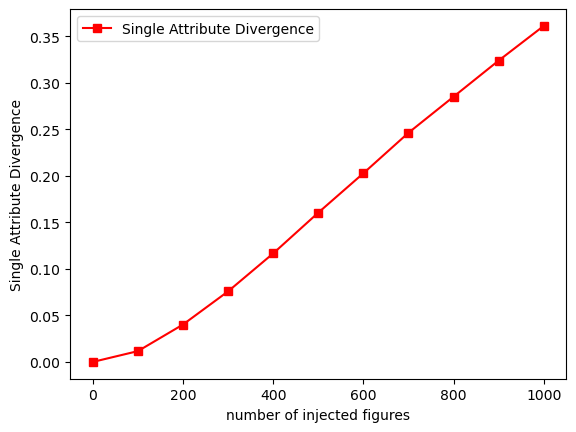

In [7]:
def my_key(dir_name):
    return int(dir_name.split('_')[-1])

x = list(range(0,1100,100))#点的横坐标
# read experiment results from the path
base_path = '/Users/yifanlu/PycharmProjects/interpretable_evaluation_metrics/results_dir/celebA_2_USER_EvalCS'
dirs = sorted((f for f in os.listdir(base_path) if f.startswith("man1k")), key=my_key)
sad = [0]
pad = [0]
for dir in dirs:
    dir_path = os.path.join(base_path, dir)
    with open(f'{dir_path}/experiment_results_dict.pkl', 'rb') as f:
        results = pickle.load(f)
        sad.append(results['kernel_distance_single'].mean())
        # pad.append(results['forward_KL_pair'].mean())       
plt.plot(x,sad,'s-',color = 'r',label="Single Attribute Divergence")    #s-:方形        
# plt.plot(x,pad,'o-',color = 'g',label="PaD")    #o-:圆形        
plt.xlabel("number of injected figures")    #横坐标名字           
plt.ylabel("Single Attribute Divergence")    #纵坐标名字                              
plt.legend(loc = "best")    #图例                              
plt.savefig('hcs_GD_FKL.png', bbox_inches='tight')            
plt.show()

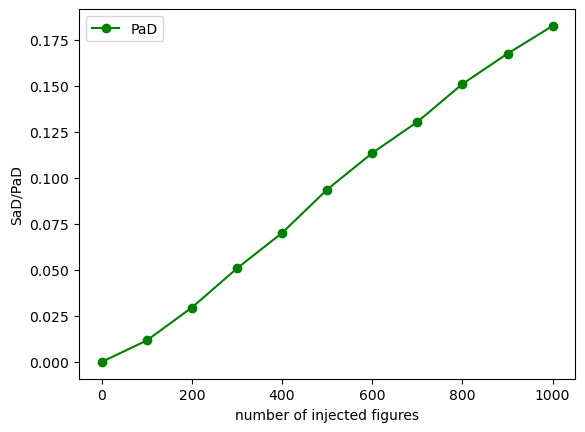

In [15]:
def my_key(dir_name):
    return int(dir_name.split('_')[-1])

x = list(range(0,1100,100))#点的横坐标
# read experiment results from the path
base_path = '/Users/yifanlu/PycharmProjects/interpretable_evaluation_metrics/results_dir/celebA_2_USER_HCS'
dirs = sorted((f for f in os.listdir(base_path) if f.startswith("man1k")), key=my_key)
pad = [0]
for dir in dirs:
    dir_path = os.path.join(base_path, dir)
    with open(f'{dir_path}/experiment_results_dict.pkl', 'rb') as f:
        results = pickle.load(f)
        pad.append(results['forward_KL_pair'].mean())             
plt.plot(x,pad,'o-',color = 'g',label="PaD")    #o-:圆形        
plt.xlabel("number of injected figures")    #横坐标名字           
plt.ylabel("SaD/PaD")    #纵坐标名字                              
plt.legend(loc = "best")    #图例                              
plt.savefig('hcs_GD_FKL.png', bbox_inches='tight')            
plt.show()

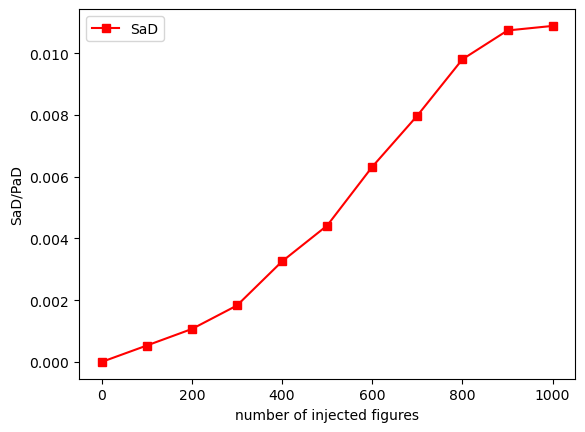

In [16]:
def my_key(dir_name):
    return int(dir_name.split('_')[-1])

x = list(range(0,1100,100))#点的横坐标
# read experiment results from the path
base_path = '/Users/yifanlu/PycharmProjects/interpretable_evaluation_metrics/results_dir/celebA_2_USER_HCS'
dirs = sorted((f for f in os.listdir(base_path) if f.startswith("man1k")), key=my_key)
sad = [0]
for dir in dirs:
    dir_path = os.path.join(base_path, dir)
    with open(f'{dir_path}/experiment_results_dict.pkl', 'rb') as f:
        results = pickle.load(f)
        sad.append(results['forward_KL_single'][0])  
plt.plot(x,sad,'s-',color = 'r',label="SaD")    #s-:方形              
plt.xlabel("number of injected figures")    #横坐标名字           
plt.ylabel("SaD/PaD")    #纵坐标名字                              
plt.legend(loc = "best")    #图例                              
plt.savefig('hcs_GD_FKL.png', bbox_inches='tight')            
plt.show()

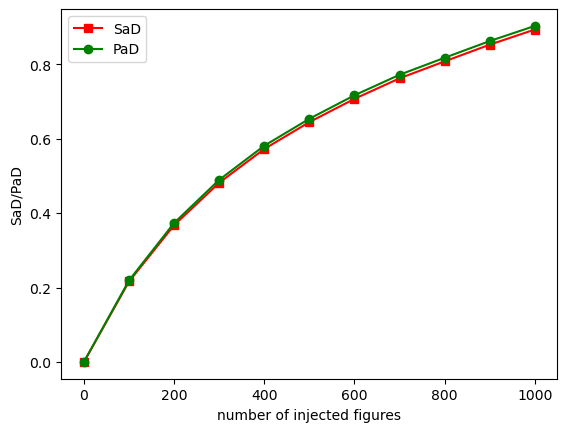

In [28]:
def my_key(dir_name):
    return int(dir_name.split('_')[-1])

x = list(range(0,1100,100))#点的横坐标
# read experiment results from the path
base_path = '/Users/yifanlu/PycharmProjects/interpretable_evaluation_metrics/results_dir/celebA_2_USER_dualCS'
dirs = sorted((f for f in os.listdir(base_path) if f.startswith("man1k")), key=my_key)
sad = [0]
pad = [0]
for dir in dirs:
    dir_path = os.path.join(base_path, dir)
    with open(f'{dir_path}/experiment_results_dict.pkl', 'rb') as f:
        results = pickle.load(f)
        sad.append(results['forward_KL_single'][0])
        pad.append(results['forward_KL_pair'][0])       
plt.plot(x,sad,'s-',color = 'r',label="SaD")    #s-:方形        
plt.plot(x,pad,'o-',color = 'g',label="PaD")    #o-:圆形        
plt.xlabel("number of injected figures")    #横坐标名字           
plt.ylabel("SaD/PaD")    #纵坐标名字                              
plt.legend(loc = "best")    #图例                              
plt.savefig('dualcs_GD_FKL.png', bbox_inches='tight')            
plt.show()

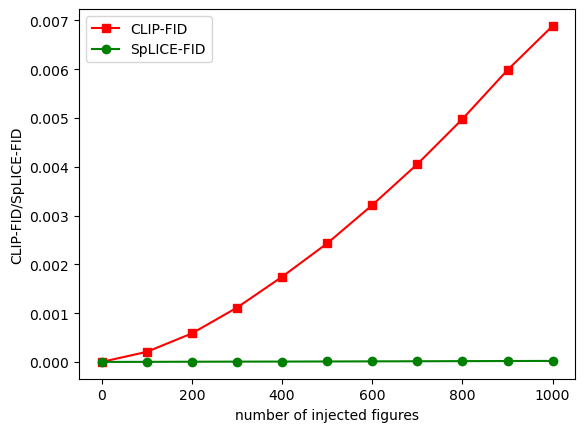

In [21]:
x = list(range(0,1100,100))#点的横坐标
# read experiment results from the path
clip_fid = [0, 0.00020636, 0.00058449, 0.001112836, 0.001745286, 0.002430090, 0.0032151975, 0.004055359185837275, 0.004979147628229952,
           0.0059844099064574755, 0.00688827903897642]
splice = [0, 1.3723705074592575e-06, 4.0801256425945745e-06, 5.946806865620489e-06, 7.104508212316553e-06, 9.046643438228823e-06, 1.146136870681143e-05,
      1.3674898586275528e-05, 1.5956719755836198e-05, 1.8577827029686947e-05, 2.0284491419677843e-05]
     
plt.plot(x,clip_fid,'s-',color = 'r',label="CLIP-FID")    #s-:方形        
plt.plot(x,splice,'o-',color = 'g',label="SpLICE-FID")    #o-:圆形        
plt.xlabel("number of injected figures")    #横坐标名字           
plt.ylabel("CLIP-FID/SpLICE-FID")    #纵坐标名字                              
plt.legend(loc = "best")    #图例                              
plt.savefig('hcs_GD_FKL.png', bbox_inches='tight')            
plt.show()

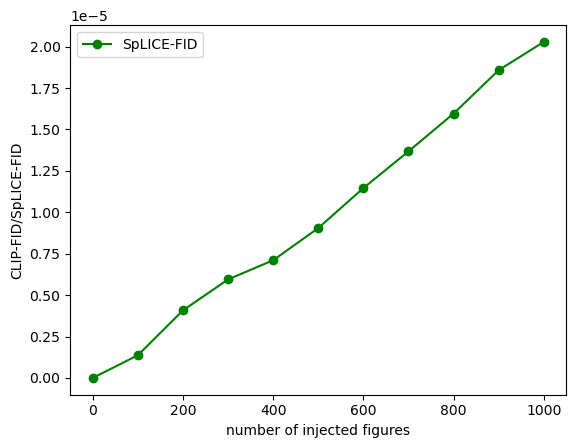

In [22]:
x = list(range(0,1100,100))#点的横坐标
# read experiment results from the path
clip_fid = [0, 0.00020636, 0.00058449, 0.001112836, 0.001745286, 0.002430090, 0.0032151975, 0.004055359185837275, 0.004979147628229952,
           0.0059844099064574755, 0.00688827903897642]
splice = [0, 1.3723705074592575e-06, 4.0801256425945745e-06, 5.946806865620489e-06, 7.104508212316553e-06, 9.046643438228823e-06, 1.146136870681143e-05,
      1.3674898586275528e-05, 1.5956719755836198e-05, 1.8577827029686947e-05, 2.0284491419677843e-05]      
plt.plot(x,splice,'o-',color = 'g',label="SpLICE-FID")    #o-:圆形        
plt.xlabel("number of injected figures")    #横坐标名字           
plt.ylabel("CLIP-FID/SpLICE-FID")    #纵坐标名字                              
plt.legend(loc = "best")    #图例                              
plt.savefig('hcs_GD_FKL.png', bbox_inches='tight')            
plt.show()

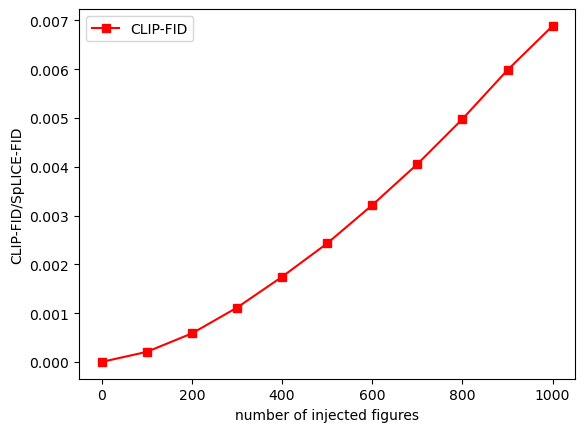

In [23]:
x = list(range(0,1100,100))#点的横坐标
# read experiment results from the path
clip_fid = [0, 0.00020636, 0.00058449, 0.001112836, 0.001745286, 0.002430090, 0.0032151975, 0.004055359185837275, 0.004979147628229952,
           0.0059844099064574755, 0.00688827903897642]
splice = [0, 1.3723705074592575e-06, 4.0801256425945745e-06, 5.946806865620489e-06, 7.104508212316553e-06, 9.046643438228823e-06, 1.146136870681143e-05,
      1.3674898586275528e-05, 1.5956719755836198e-05, 1.8577827029686947e-05, 2.0284491419677843e-05]
     
plt.plot(x,clip_fid,'s-',color = 'r',label="CLIP-FID")    #s-:方形                
plt.xlabel("number of injected figures")    #横坐标名字           
plt.ylabel("CLIP-FID/SpLICE-FID")    #纵坐标名字                              
plt.legend(loc = "best")    #图例                              
plt.savefig('hcs_GD_FKL.png', bbox_inches='tight')            
plt.show()